# Day 102 — Multi Layer Perceptron | MLP Intuition

Why do hidden layers make a network powerful? In this notebook we build the intuition step by step:

1. **Hidden layers re-represent the data**: XOR becomes linearly separable in hidden space
2. **Combining perceptrons**: each neuron is a soft half-plane, and the output neuron combines them
3. **Width**: more hidden neurons approximate more complex regions (polygon-to-circle demo)
4. **Trained width experiment** on circles and moons
5. **Depth**: deeper networks on a harder dataset (two spirals)
6. **Function approximation**: sums of sigmoid "steps" build any curve (universal approximation idea)
7. **Other ways to extend an MLP**: multiple outputs and skip connections

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles, make_moons
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.model_selection import train_test_split

np.random.seed(42)

def sigmoid(z): return 1 / (1 + np.exp(-z))

def plot_region(ax, predict_fn, X, y, title, pad=0.4):
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, 300),
                         np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, 300))
    Z = predict_fn(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k", s=18)
    ax.set_title(title)

## 1. Hidden layers re-represent the data (XOR)

A single perceptron cannot solve XOR in the original space. A hidden layer with two neurons maps each point `(x1, x2)` to new coordinates `(h1, h2)`.
We use the hand-set weights from Day 97 but with steep sigmoids:

- `h1` ≈ OR(x1, x2)
- `h2` ≈ NAND(x1, x2)

Accuracy of the 2-layer network on noisy XOR: 0.955


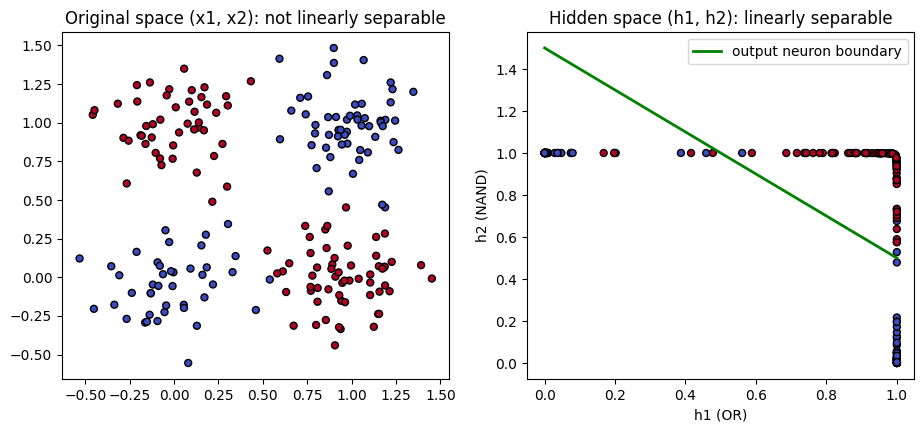

In [2]:
def make_xor(n=200, noise=0.2, seed=0):
    rng = np.random.RandomState(seed)
    X = rng.randint(0, 2, size=(n, 2)).astype(float)
    y = X[:, 0].astype(int) ^ X[:, 1].astype(int)
    return X + rng.randn(n, 2) * noise, y

X_xor, y_xor = make_xor()

def hidden_layer(X, k=10):
    h1 = sigmoid(k * (X[:, 0] + X[:, 1] - 0.5))        # ~ OR
    h2 = sigmoid(k * (1.5 - X[:, 0] - X[:, 1]))        # ~ NAND
    return np.c_[h1, h2]

H = hidden_layer(X_xor)

def output_neuron(H, k=10):
    return sigmoid(k * (H[:, 0] + H[:, 1] - 1.5))      # ~ AND of the two hidden units

pred = (output_neuron(H) >= 0.5).astype(int)
print("Accuracy of the 2-layer network on noisy XOR:", (pred == y_xor).mean())

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(X_xor[:, 0], X_xor[:, 1], c=y_xor, cmap="coolwarm", edgecolor="k", s=25)
axes[0].set_title("Original space (x1, x2): not linearly separable")
axes[1].scatter(H[:, 0], H[:, 1], c=y_xor, cmap="coolwarm", edgecolor="k", s=25)
hx = np.linspace(0, 1, 50)
axes[1].plot(hx, 1.5 - hx, "g-", lw=2, label="output neuron boundary")
axes[1].set_xlabel("h1 (OR)"); axes[1].set_ylabel("h2 (NAND)")
axes[1].set_title("Hidden space (h1, h2): linearly separable"); axes[1].legend()
plt.show()

**Key intuition:** the hidden layer *transforms* the data into a new space where a single linear neuron (the output layer) is enough.

## 2. Combining perceptrons: each neuron is a soft half-plane

Each hidden neuron `σ(w·x + b)` splits the plane into two sides. The output neuron combines these maps.
Below: two neurons with different lines, and their combination (like an AND, giving a wedge-shaped region).

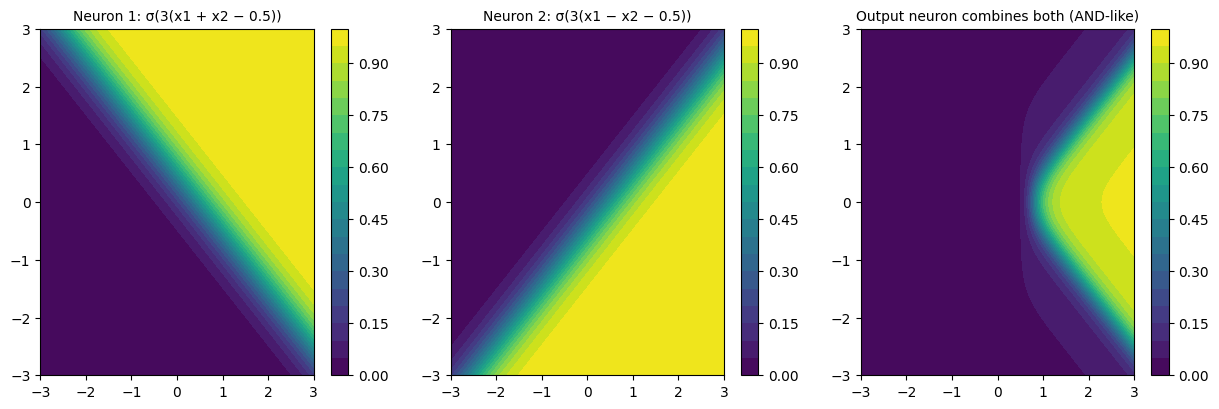

In [3]:
xx, yy = np.meshgrid(np.linspace(-3, 3, 300), np.linspace(-3, 3, 300))
grid = np.c_[xx.ravel(), yy.ravel()]

n1 = sigmoid(3 * (grid @ np.array([1.0, 1.0]) - 0.5)).reshape(xx.shape)      # line x1 + x2 = 0.5
n2 = sigmoid(3 * (grid @ np.array([1.0, -1.0]) - 0.5)).reshape(xx.shape)     # line x1 - x2 = 0.5
combined = sigmoid(6 * (n1 + n2 - 1.5))                                       # AND-like combination

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, data, title in zip(axes, [n1, n2, combined],
                           ["Neuron 1: σ(3(x1 + x2 − 0.5))", "Neuron 2: σ(3(x1 − x2 − 0.5))", "Output neuron combines both (AND-like)"]):
    cs = ax.contourf(xx, yy, data, levels=20, cmap="viridis")
    ax.set_title(title, fontsize=10); plt.colorbar(cs, ax=ax)
plt.show()

## 3. Width: more hidden neurons, more complex regions

Idea: every hidden neuron is a half-plane `w·x ≤ r`. An AND of `k` half-planes forms a **convex polygon**. As `k` grows, the polygon approaches a circle.

We build this by hand (no training) to classify two concentric circles.

hidden neurons k | accuracy on circles (inner class = 1)
               3 | 0.833
               4 | 0.953
               5 | 1.000
               6 | 1.000
               8 | 1.000
              12 | 1.000
              20 | 1.000
              50 | 1.000


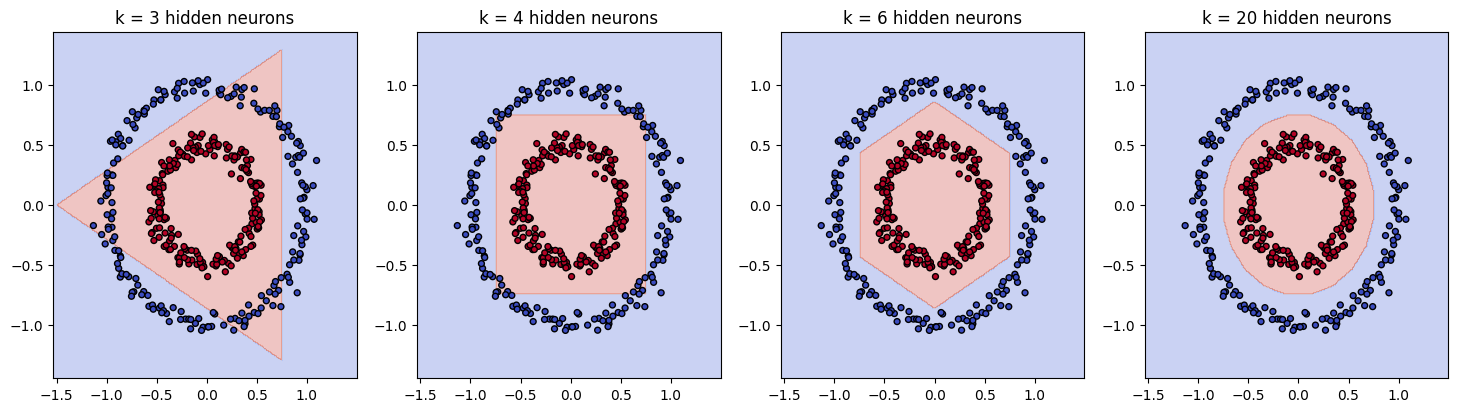

In [4]:
Xc, yc = make_circles(n_samples=400, noise=0.05, factor=0.5, random_state=1)
r = 0.75                                                   # between inner (0.5) and outer (1.0) radius

def polygon_net(X, k):
    angles = np.linspace(0, 2 * np.pi, k, endpoint=False)
    W = np.c_[np.cos(angles), np.sin(angles)]              # k hidden neurons (unit normals)
    H = (X @ W.T <= r).astype(float)                       # each neuron: 1 if inside its half-plane
    return (H.sum(axis=1) >= k - 0.5).astype(int)          # output neuron: AND of all k neurons

print(f"{'hidden neurons k':>16} | accuracy on circles (inner class = 1)")
for k in [3, 4, 5, 6, 8, 12, 20, 50]:
    acc = (polygon_net(Xc, k) == yc).mean()                # make_circles: label 1 = inner circle, 0 = outer circle
    print(f"{k:16d} | {acc:.3f}")

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, k in zip(axes, [3, 4, 6, 20]):
    plot_region(ax, lambda P, k=k: polygon_net(P, k), Xc, yc, f"k = {k} hidden neurons")
plt.show()

## 4. Width, trained: how many hidden neurons are enough?

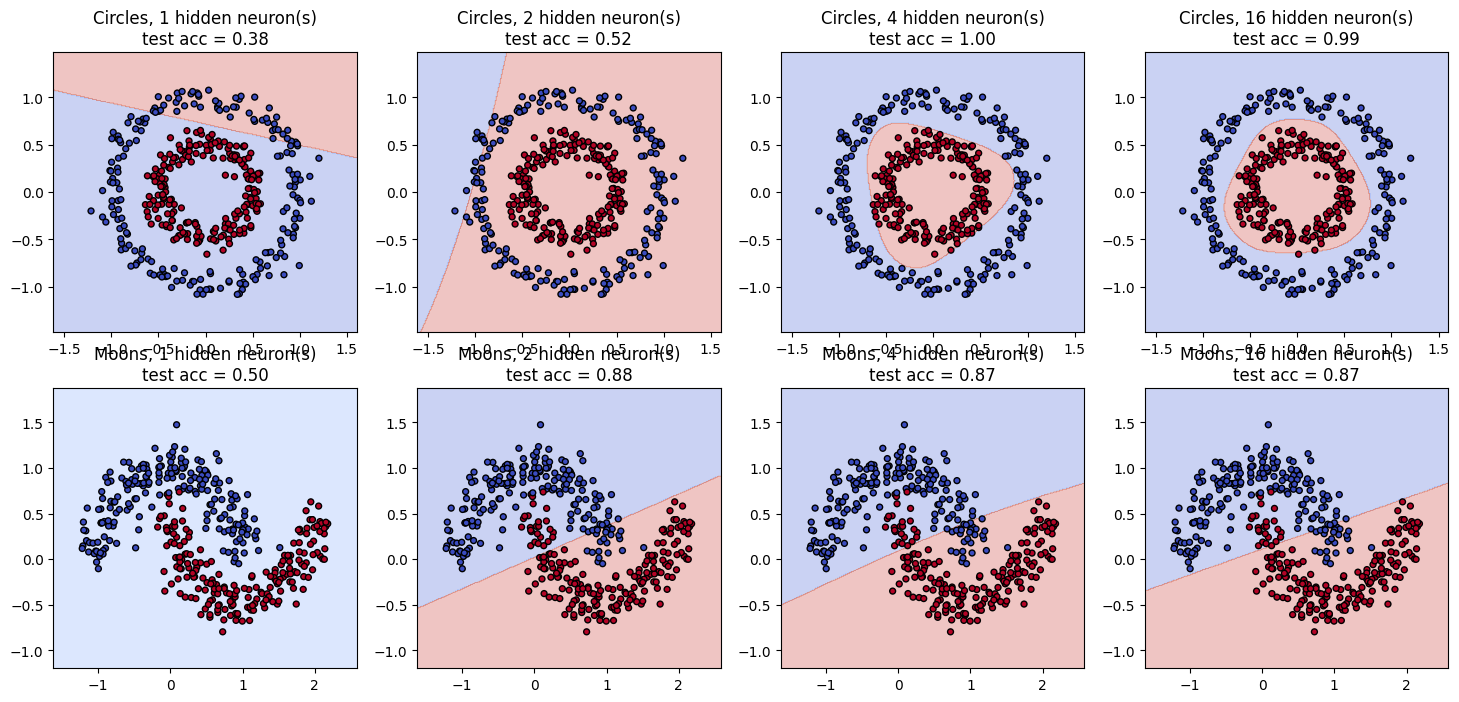

In [5]:
datasets = {"Circles": make_circles(n_samples=400, noise=0.08, factor=0.5, random_state=1),
            "Moons": make_moons(n_samples=400, noise=0.15, random_state=1)}

widths = [1, 2, 4, 16]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for r_i, (name, (X, y)) in enumerate(datasets.items()):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
    for c_i, w in enumerate(widths):
        clf = MLPClassifier(hidden_layer_sizes=(w,), activation="tanh", max_iter=5000, random_state=0).fit(X_tr, y_tr)
        plot_region(axes[r_i, c_i], clf.predict, X, y, f"{name}, {w} hidden neuron(s)\ntest acc = {clf.score(X_te, y_te):.2f}")
plt.show()

## 5. Depth: a harder problem (two spirals)

Two interleaved spirals need a very twisty boundary. We compare a shallow-wide network with deeper ones.

    architecture | parameters | train acc | test acc
            (2,) |          9 |     0.664 |    0.628
            (8,) |         33 |     0.938 |    0.906
           (64,) |        257 |     1.000 |    1.000
        (16, 16) |        337 |     1.000 |    0.994
    (16, 16, 16) |        609 |     1.000 |    0.989


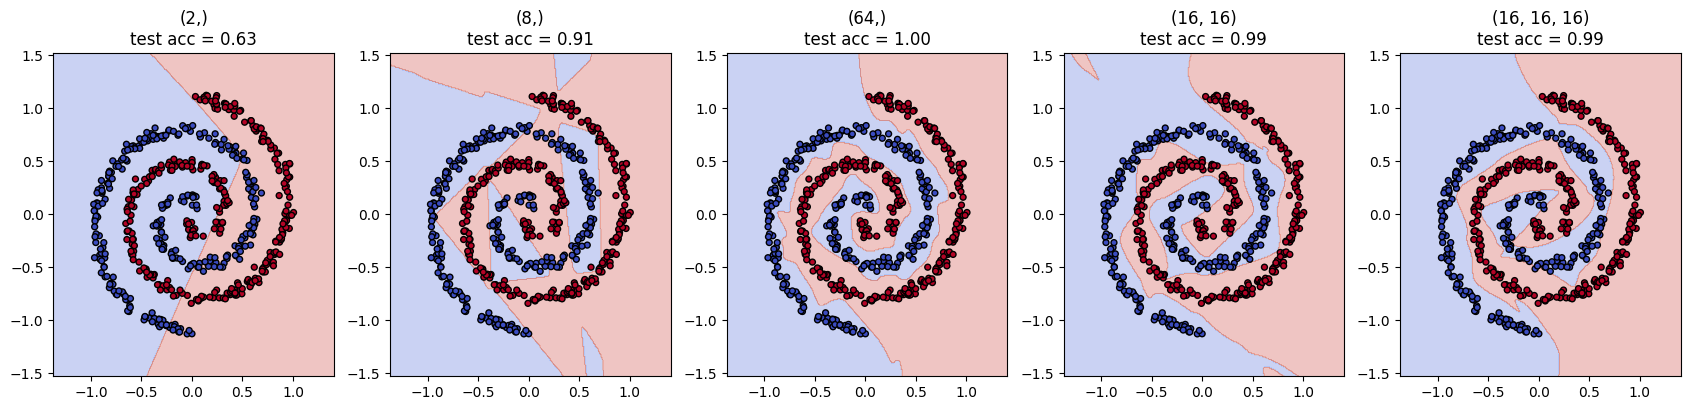

In [6]:
def make_spirals(n=300, noise=0.15, turns=1.75, seed=0):
    rng = np.random.RandomState(seed)
    t = np.sqrt(rng.rand(n)) * turns * 2 * np.pi
    X0 = np.c_[t * np.cos(t), t * np.sin(t)] / 10
    X1 = np.c_[-t * np.cos(t), -t * np.sin(t)] / 10
    X = np.r_[X0, X1] + rng.randn(2 * n, 2) * noise / 5
    y = np.r_[np.zeros(n), np.ones(n)].astype(int)
    return X, y

X_sp, y_sp = make_spirals()
X_tr, X_te, y_tr, y_te = train_test_split(X_sp, y_sp, test_size=0.3, random_state=0, stratify=y_sp)

archs = [(2,), (8,), (64,), (16, 16), (16, 16, 16)]
fig, axes = plt.subplots(1, len(archs), figsize=(4.2 * len(archs), 4.2))
print(f"{'architecture':>16} | {'parameters':>10} | train acc | test acc")
for ax, arch in zip(axes, archs):
    clf = MLPClassifier(hidden_layer_sizes=arch, activation="tanh", max_iter=8000, solver="lbfgs", random_state=0).fit(X_tr, y_tr)
    n_params = sum(w.size for w in clf.coefs_) + sum(b.size for b in clf.intercepts_)
    print(f"{str(arch):>16} | {n_params:10d} | {clf.score(X_tr, y_tr):9.3f} | {clf.score(X_te, y_te):8.3f}")
    plot_region(ax, clf.predict, X_sp, y_sp, f"{arch}\ntest acc = {clf.score(X_te, y_te):.2f}")
plt.show()

Results depend on the random start and on the optimizer, so treat this as an illustration, not a benchmark.
Rule of thumb: more capacity (width or depth) lets the network fit more complex boundaries, but also raises the risk of **overfitting** and needs more data and tuning.

## 6. Function approximation: building curves from sigmoid steps

A very steep sigmoid acts like a **step**. The difference of two steps is a **bump**. A sum of bumps (each with the height of the target function) approximates any smooth curve. This is the intuition behind the **Universal Approximation Theorem**.

 bumps | hidden neurons | max error
     2 |              4 | 0.967
     4 |              8 | 0.676
     8 |             16 | 0.356
    32 |             64 | 0.077


C:\Users\DELL\AppData\Local\Temp\ipykernel_8704\3377201336.py:9: RuntimeWarning: overflow encountered in exp
  def sigmoid(z): return 1 / (1 + np.exp(-z))


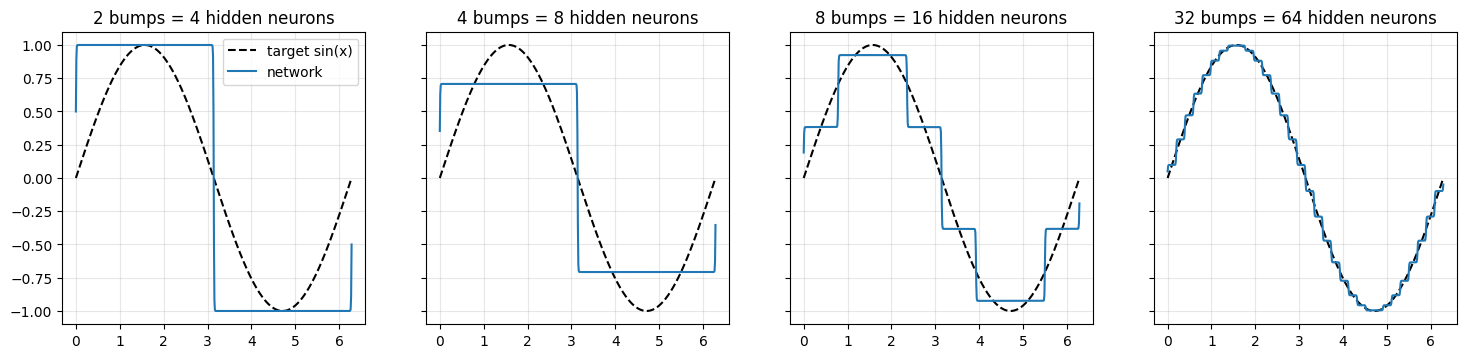

In [7]:
f = np.sin
x = np.linspace(0, 2 * np.pi, 600)
steepness = 200

def bump_approximation(x, n_bumps):
    edges = np.linspace(0, 2 * np.pi, n_bumps + 1)
    out = np.zeros_like(x)
    for lo, hi in zip(edges[:-1], edges[1:]):
        height = f((lo + hi) / 2)
        out += height * (sigmoid(steepness * (x - lo)) - sigmoid(steepness * (x - hi)))   # two hidden neurons per bump
    return out

fig, axes = plt.subplots(1, 4, figsize=(18, 3.8), sharey=True)
print(f"{'bumps':>6} | {'hidden neurons':>14} | max error")
for ax, nb in zip(axes, [2, 4, 8, 32]):
    approx = bump_approximation(x, nb)
    err = np.abs(approx - f(x)).max()
    print(f"{nb:6d} | {2 * nb:14d} | {err:.3f}")
    ax.plot(x, f(x), "k--", label="target sin(x)"); ax.plot(x, approx, label="network")
    ax.set_title(f"{nb} bumps = {2 * nb} hidden neurons"); ax.grid(alpha=0.3)
axes[0].legend(); plt.show()

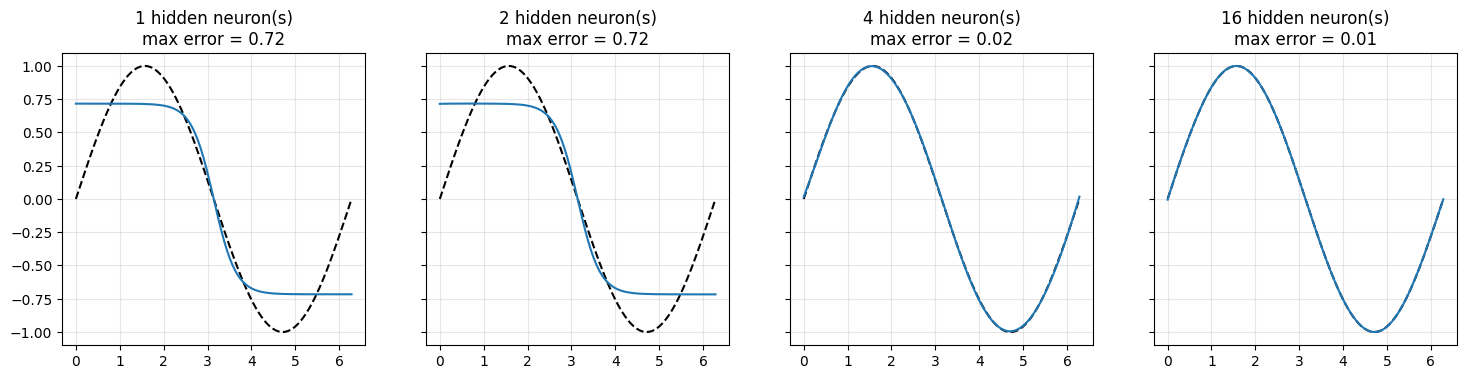

In [8]:
# The same idea with a trained network (one hidden layer)
X_1d = np.linspace(0, 2 * np.pi, 200).reshape(-1, 1)
y_1d = np.sin(X_1d).ravel()

fig, axes = plt.subplots(1, 4, figsize=(18, 3.8), sharey=True)
for ax, n_h in zip(axes, [1, 2, 4, 16]):
    reg = MLPRegressor(hidden_layer_sizes=(n_h,), activation="tanh", solver="lbfgs", max_iter=5000, random_state=0).fit(X_1d, y_1d)
    ax.plot(X_1d, y_1d, "k--"); ax.plot(X_1d, reg.predict(X_1d))
    ax.set_title(f"{n_h} hidden neuron(s)\nmax error = {np.abs(reg.predict(X_1d) - y_1d).max():.2f}"); ax.grid(alpha=0.3)
plt.show()

## 7. Other ways to extend an MLP

**Multiple outputs:** the output layer can have several nodes (multi-class classification, multi-label, or multi-target regression).

**Skip connections:** feed an earlier layer directly into a later one, `a² = f(W₂ a¹ + W_skip · x + b)`. This idea powers ResNets.

In [9]:
rng = np.random.RandomState(0)
X_demo = rng.randn(6, 4)

# Multiple outputs: 4 -> 5 -> 3 (softmax over 3 classes)
W1, b1 = rng.randn(4, 5), np.zeros(5)
W2, b2 = rng.randn(5, 3), np.zeros(3)
def softmax(Z):
    e = np.exp(Z - Z.max(axis=1, keepdims=True)); return e / e.sum(axis=1, keepdims=True)

A1 = np.tanh(X_demo @ W1 + b1)
probs = softmax(A1 @ W2 + b2)
print("Multi-output (3 classes) shape:", probs.shape, "| each row sums to 1:", np.allclose(probs.sum(axis=1), 1))

# Skip connection: the input is also fed straight to the output layer
W_skip = rng.randn(4, 3)
probs_skip = softmax(A1 @ W2 + X_demo @ W_skip + b2)
print("With skip connection shape  :", probs_skip.shape)
print("Output differs from the plain version:", not np.allclose(probs, probs_skip))

Multi-output (3 classes) shape: (6, 3) | each row sums to 1: True
With skip connection shape  : (6, 3)
Output differs from the plain version: True


## Summary

| Idea | Intuition |
|---|---|
| Hidden layer | Re-represents the data in a new space where it is (more) linearly separable |
| Each hidden neuron | A soft half-plane / feature detector |
| Output neuron | Combines hidden features (AND / OR-like) |
| More width | More half-planes, so more complex regions (polygon to circle) |
| More depth | Features of features, so more twisty boundaries |
| Non-linear activation | Required, otherwise all layers collapse into one linear map |
| Universal approximation | Enough hidden neurons can approximate any continuous function |

## Practice exercises

1. In section 3, change the radius `r` to 0.6 and 0.9. What happens to the accuracy for small `k`?
2. Replace `tanh` with `identity` in section 4. Why does the network behave like a single perceptron?
3. Add an interactive-style loop: train `(4,)`, `(4, 4)`, `(4, 4, 4)` on spirals and compare test accuracy.
4. In section 6, use a different target (`np.cos(x) + 0.5 * np.sin(3 * x)`) and see how many bumps are needed for a max error under 0.1.
5. Visit the TensorFlow Playground and reproduce the XOR, circle and spiral experiments with 1, 2 and 3 hidden layers.